### Setup

In [14]:
import copy, math, os, time
from pathlib import Path
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
import matplotlib.pyplot as plt
import urllib.request

torch.manual_seed(5561)
dev = "cuda" if torch.cuda.is_available() else "mps" if torch.backends.mps.is_available() else "cpu"
print("device:", dev)


def show_grid(x, title="", rows=8):
    # x: (n, 1, 28, 28) in [-1, 1]
    g = torchvision.utils.make_grid(x[:rows * rows].detach().float().cpu(), nrow=rows,
                                    padding=2, pad_value=1)
    plt.figure(figsize=(5, 5)); plt.imshow(g[0], cmap="gray", vmin=-1, vmax=1)
    plt.title(title); plt.axis("off"); plt.show()


if not Path("mnist_classifier.pt").is_file():
    urllib.request.urlretrieve(
        "https://raw.githubusercontent.com/SJGuy-UMN/CSCI5561/main/mnist_classifier.pt",
        "mnist_classifier.pt",
    )
clf = torch.jit.load("mnist_classifier.pt", map_location="cpu").eval()


device: cuda


torch.Size([60000, 1, 28, 28]) -1.0 1.0


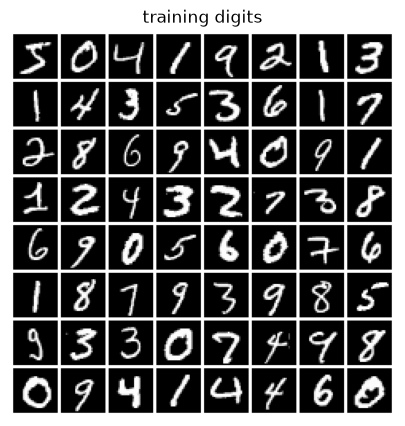

In [3]:
train = torchvision.datasets.MNIST("data", train=True, download=True)

def to_net(u8):                     # uint8 0-255  ->  float [-1, 1], shape (n, 1, 28, 28)
    return (u8.float() / 127.5 - 1).unsqueeze(1)

X = to_net(train.data)             # shared CPU copy
print(X.shape, X.min().item(), X.max().item())
show_grid(X, "training digits")
test = torchvision.datasets.MNIST("data", train=False, download=True)
xtr, xte = X, to_net(test.data)


### 1. Two-Dimensional Flow Matching 

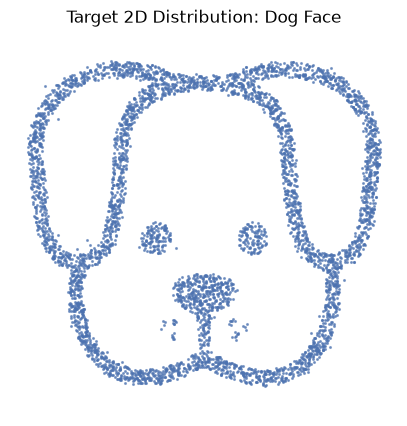

In [4]:
from PIL import Image

def sample_dog_face(batch_size, image_path="dog_face.png"):
    # 1. Load image and invert so dog = 1 (high probability), background = 0
    img = Image.open(image_path).convert("L")
    arr = 1.0 - (np.array(img, dtype=np.float32) / 255.0)
    
    # 2. Convert to probability distribution
    probs = (arr / arr.sum()).ravel()
    
    # 3. Sample pixel indices
    indices = np.random.choice(arr.size, size=batch_size, p=probs)
    y, x = np.unravel_index(indices, arr.shape)
    
    # 4. Add small jitter so points are continuous, flip y so it is upright
    pts = np.stack([
        x + np.random.uniform(-0.5, 0.5, size=batch_size),
        -y + np.random.uniform(-0.5, 0.5, size=batch_size)
    ], axis=1)
    
    # 5. Standardize to mean 0, std 1 (standard for flow matching)
    pts = (pts - pts.mean(0)) / pts.std(0)
    return torch.tensor(pts, dtype=torch.float32)

# --- Visualize your target distribution ---
target_points = sample_dog_face(5000)
plt.figure(figsize=(5, 5))
plt.scatter(target_points[:, 0], target_points[:, 1], s=1.5, alpha=0.6, color="#4C72B0")
plt.title("Target 2D Distribution: Dog Face")
plt.axis("equal")
plt.axis("off")
plt.show()



In [ ]:
from IPython.terminal import interactiveshell
def flow_matching_2D():
    class Net(nn.Module):
        def __init__(self, hidden=128):
            super().__init__()
            self.mlp = nn.Sequential(
                nn.Linear(3, hidden),
                nn.ReLU(),
                nn.Linear(hidden, hidden),
                nn.ReLU(),
                nn.Linear(hidden, hidden),
                nn.ReLU(),
                nn.Linear(hidden, 2),
            )

        def forward(self, x):
            return self.mlp(x)


    def train(net, steps=4000):
        opt = torch.optim.Adam(net.parameters(), lr=1e-3)
        for step in range(steps):
            x1 = sample_dog_face(512).to(dev)
            x0 = torch.randn_like(x1)
            t = torch.rand(len(x1), 1, device=dev)
            xt = (1 - t) * x0 + t * x1
            target = x1 - x0
            loss = ((net(torch.cat([xt, t], 1)) - target) ** 2).mean()
            opt.zero_grad(); loss.backward(); opt.step()
        return loss.item()


    @torch.no_grad()
    def sample(model, x, N=50):
        # Euler: N steps of size 1/N from noise at t = 0 to data at t = 1
        for i in range(N):
            t = torch.full((len(x), 1), i / N, device=x.device)
            x = x + model(torch.cat([x, t], 1)) / N 
        return x

    
    @torch.no_grad()
    def plot_comparison(net, n_samples=2000):
        net.eval()
        # 1. Sample true data
        true_pts = sample_dog_face(n_samples).numpy()
        
        # 2. Generate samples from pure Gaussian noise
        z0 = torch.randn(n_samples, 2, device=dev)
        gen_pts = sample(net, z0, N=50).cpu().numpy()
        
        fig, axes = plt.subplots(1, 2, figsize=(10, 5))
        
        axes[0].scatter(true_pts[:, 0], true_pts[:, 1], s=2, alpha=0.5, color="#1f77b4")
        axes[0].set_title(f"True Distribution ({n_samples} points)", fontsize=13)
        axes[0].set_xlim(-3, 3); axes[0].set_ylim(-3, 3)
        axes[0].set_aspect("equal"); axes[0].grid(True, alpha=0.3)
        
        axes[1].scatter(gen_pts[:, 0], gen_pts[:, 1], s=2, alpha=0.5, color="#ff7f0e")
        axes[1].set_title(f"Generated via Flow Matching ({n_samples} points)", fontsize=13)
        axes[1].set_xlim(-3, 3); axes[1].set_ylim(-3, 3)
        axes[1].set_aspect("equal"); axes[1].grid(True, alpha=0.3)
        
        plt.tight_layout()
        plt.show()


    @torch.no_grad()
    def plot_velocity_fields(net, grid_size=25, lim=2.5):
        net.eval()
        # Create 2D coordinate grid
        x_vals = np.linspace(-lim, lim, grid_size)
        y_vals = np.linspace(-lim, lim, grid_size)
        X, Y = np.meshgrid(x_vals, y_vals)
        pts = torch.tensor(np.stack([X.ravel(), Y.ravel()], axis=1), dtype=torch.float32, device=dev)
        
        times = [0.0, 0.5, 1.0]
        fig, axes = plt.subplots(1, 3, figsize=(15, 5))
        
        for ax, t_val in zip(axes, times):
            t = torch.full((len(pts), 1), t_val, device=dev)
            # Predict velocity vector (u, v)
            vel = net(torch.cat([pts, t], dim=1)).cpu().numpy()
            U = vel[:, 0].reshape(grid_size, grid_size)
            V = vel[:, 1].reshape(grid_size, grid_size)
            
            # Normalize arrows slightly for clean visualization
            speed = np.sqrt(U**2 + V**2) + 1e-5
            
            ax.quiver(X, Y, U, V, speed, cmap="viridis", alpha=0.85)
            ax.set_title(f"Velocity Field at t = {t_val}", fontsize=13)
            ax.set_xlim(-lim, lim); ax.set_ylim(-lim, lim)
            ax.set_aspect("equal"); ax.grid(True, alpha=0.2)
            
        plt.tight_layout()
        plt.show()

    
    @torch.no_grad()
    def plot_trajectories(net, n_paths=120, steps=50):
        net.eval()
        # 1. Fixed starting noise samples at t=0
        torch.manual_seed(42)
        x = torch.randn(n_paths, 2, device=dev)
        
        # 2. Record every intermediate integration step
        traj = [x.cpu().numpy()]
        dt = 1.0 / steps
        for i in range(steps):
            t = torch.full((len(x), 1), i * dt, device=dev)
            v = net(torch.cat([x, t], dim=1))
            x = x + v * dt
            traj.append(x.cpu().numpy())
            
        traj = np.array(traj)  # shape: (steps + 1, n_paths, 2)
        
        # 3. Plot paths
        plt.figure(figsize=(7, 7))
        
        # Plot target distribution faintly in background for reference
        true_ref = sample_dog_face(1500).numpy()
        plt.scatter(true_ref[:, 0], true_ref[:, 1], s=1, color="lightgray", alpha=0.5, label="Target Dog Shape")
        
        # Plot individual trajectories
        for i in range(n_paths):
            plt.plot(traj[:, i, 0], traj[:, i, 1], color="#2b5c8f", alpha=0.35, lw=1)
            
        # Mark start points (t=0) and end points (t=1)
        plt.scatter(traj[0, :, 0], traj[0, :, 1], s=16, color="#d95f02", label="Initial Noise (t=0)", zorder=3)
        plt.scatter(traj[-1, :, 0], traj[-1, :, 1], s=16, color="#1b9e77", label="Final Generated (t=1)", zorder=4)
        
        plt.title(f"Flow Trajectories ({n_paths} samples)", fontsize=13)
        plt.xlim(-3, 3); plt.ylim(-3, 3)
        plt.gca().set_aspect("equal")
        plt.legend(loc="upper right", framealpha=0.9)
        plt.grid(True, alpha=0.25)
        plt.show()

    
    net = Net().to(dev)
    print(f"{sum(p.numel() for p in net.parameters()):,} weights")

    final_loss = train(net, steps=4000)
    print(f"Training complete. Final loss: {final_loss:.4f}")

    plot_comparison(net)
    plot_velocity_fields(net)
    plot_trajectories(net, n_paths=120)




33,794 weights
Training complete. Final loss: 1.3736


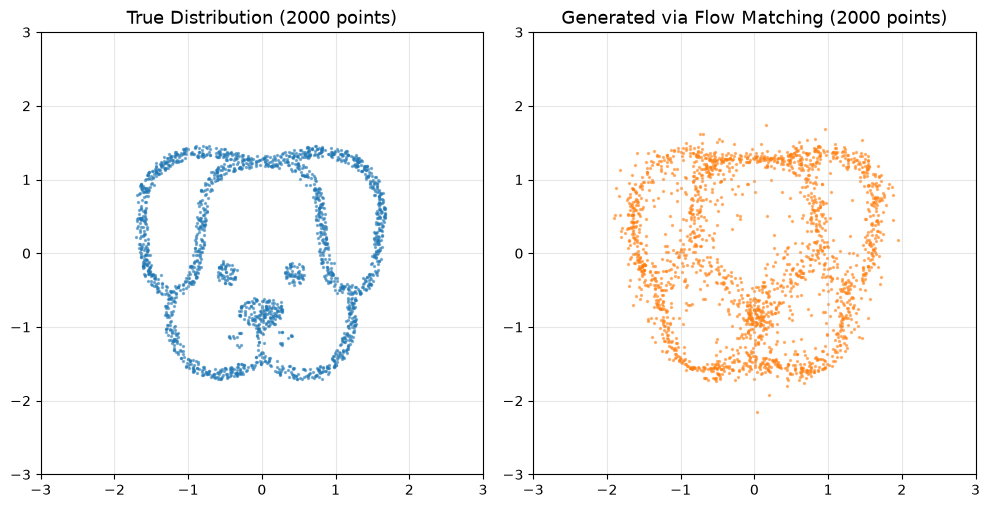

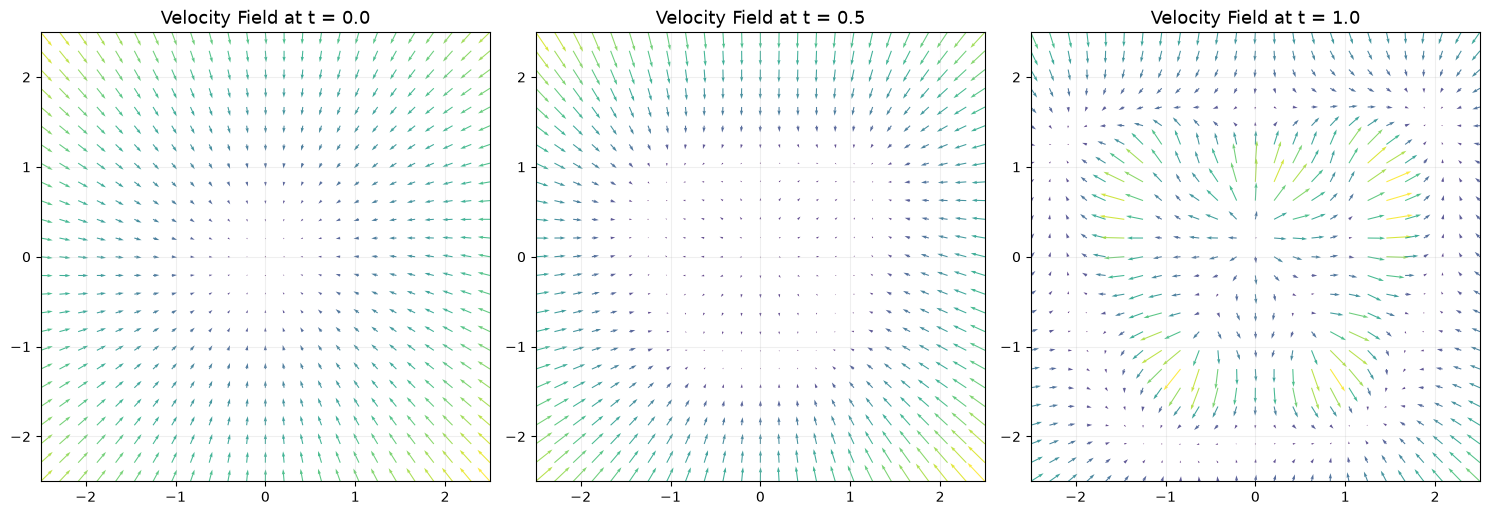

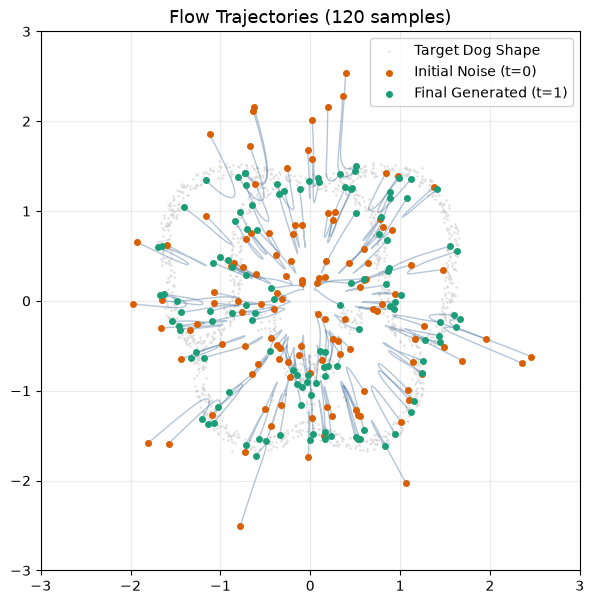

In [19]:
flow_matching_2D()

### 2. Image Model and Training Diagnostics 

### 3. Unconditional Image Generation 

### 4. Basic Performance Tuning